Índices sorteados (indices_tx): [ 63  88 142 255  32]
Símbolos limpos (S_t):          [ 1.1504-0.6903j  0.0767-0.3835j  0.9971+0.0767j  1.1504+1.1504j
 -1.1504-0.8437j]
Símbolos com ruído (r):         [ 1.1536-0.7031j  0.0782-0.3944j  1.0068+0.0821j  1.1499+1.1314j
 -1.1453-0.8536j]
Símbolos decodificados: [ 1.1504-0.6903j  0.0767-0.3835j  0.9971+0.0767j  1.1504+1.1504j
 -1.1504-0.8437j]
Total de erros: 0 de 1000000 | SER = 0.0


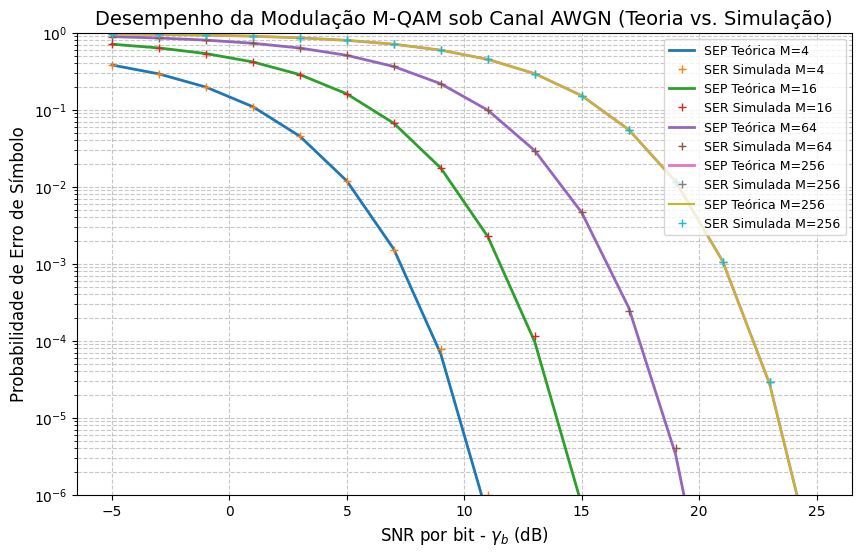

In [1]:
import numpy as np
from scipy.special import erfc
import matplotlib.pyplot as plt

def gerar_constelacao(M):

    L = int(np.sqrt(M))
    energia_media_da_constelacao = 1
    d = np.sqrt((3 * energia_media_da_constelacao) / (2 * (M - 1)))

    eixo = d * np.arange(-(L-1), L, 2 )
    I, Q = np.meshgrid(eixo, eixo)

    C = (I + 1j * Q).flatten()

    return C

def Q(x):
  return 0.5 * erfc(x / np.sqrt(2))

def calcular_sep_teorica(M, snr_simbolo):
  termo_M = 1 - (1 / np.sqrt(M))
  arg_Q = np.sqrt((3 / (M - 1)) * snr_simbolo)
  q_val = Q(arg_Q)

  sep = 4 * termo_M * q_val - 4 * (termo_M**2) * (q_val**2)
  return sep

N_t = 10**6
ordens_M = [4, 16, 64, 256]
snr_db_vetor = np.arange(-5, 26, 2)

plt.figure(figsize=(10, 6))

for M in ordens_M:
    C = gerar_constelacao(M)
    indices_tx = np.random.randint(0, M, size = N_t)
    S_t = C[indices_tx]
    ser_simulada = []
    sep_teorica = []

    for snr_db in snr_db_vetor:
        snr_linear = 10**(snr_db / 10)
        snr_simbolo = snr_linear * np.log2(M)

        # sigma_n é o desvio padrão do ruido
        sigma_n = np.sqrt(1 /( 2 * snr_simbolo))

        n_real = np.random.normal(0, sigma_n, size=N_t)
        n_imag = 1j * np.random.normal(0, sigma_n, size=N_t)
        n = n_real + n_imag

        r = S_t + n

        distancias_quadrado = np.abs(r[:, None] - C[None, :]) ** 2
        indice_minimo = np.argmin(distancias_quadrado, axis=1)
        simbolos_decodificados = C[indice_minimo]
        N_erros = np.sum(S_t != simbolos_decodificados)
        SER = N_erros / N_t
        ser_simulada.append(SER)

        SEP = calcular_sep_teorica(M, snr_simbolo)
        sep_teorica.append(SEP)
    plt.semilogy(
      snr_db_vetor,
      sep_teorica,
      '-',
      label=f'SEP Teórica M={M}',
      linewidth=2,
    )
    plt.semilogy(snr_db_vetor, ser_simulada, '+', label=f'SER Simulada M={M}')

print("Índices sorteados (indices_tx):", indices_tx[:5])
print("Símbolos limpos (S_t):         ", np.round(S_t[:5], 4))
print("Símbolos com ruído (r):        ", np.round(r[:5], 4))

print("Símbolos decodificados:", np.round(simbolos_decodificados[:5], 4))
print(f"Total de erros: {N_erros} de {N_t} | SER = {SER}")

plt.semilogy(snr_db_vetor, sep_teorica, '-', label=f'SEP Teórica M={M}')
plt.semilogy(snr_db_vetor, ser_simulada, '+', label=f'SER Simulada M={M}')

plt.xlabel(r'SNR por bit - $\gamma_b$ (dB)', fontsize=12)
plt.ylabel('Probabilidade de Erro de Símbolo', fontsize=12)
plt.title(
    'Desempenho da Modulação M-QAM sob Canal AWGN (Teoria vs. Simulação)',
    fontsize=14,
)
plt.grid(True, which='both', linestyle='--', alpha=0.7)
plt.ylim(1e-6, 1)
plt.legend(loc='upper right', fontsize=9)
plt.show()